# TP2 â€” Retrieval-Augmented Generation (Part 1)
## From Documents to a Searchable Knowledge Base

**Module 2IAiasd 9.7 â€” Agentic AI Â· IMT Mines AlÃ¨s**  
**Duration:** 2 h  
**Prerequisites:** TP1 completed (ReAct agent with `bind_tools`)

---

### What you will build today

By the end of this session your internship report will be **searchable by meaning**, not just by keyword.  
You will have:

1. Loaded and inspected your PDF with `PyPDFLoader`
2. Split it into chunks using two different strategies
3. Embedded every chunk with `nomic-embed-text` via Ollama
4. Stored and persisted the vectors in a **ChromaDB** collection
5. Run your first semantic retriever and compared chunking strategies

### The bigger picture

```
  Your PDF
     â”‚
     â–¼
  [Load]  â”€â”€â–º  pages (list of Document objects)
     â”‚
     â–¼
  [Chunk]  â”€â”€â–º  smaller pieces  (recursive  |  semantic)
     â”‚
     â–¼
  [Embed]  â”€â”€â–º  vectors  (nomic-embed-text via Ollama)
     â”‚
     â–¼
  [Index]  â”€â”€â–º  ChromaDB  (persisted on disk)
     â”‚
     â–¼
  [Retrieve]  â”€â”€â–º  top-k chunks for a query
```

Part 2 (Thursday) adds the LLM on top to answer questions and evaluates the full pipeline with RAGAS.

---

> **Your document:** Use your **2A internship report** (PDF).  
> Place it in the same folder as this notebook and update `PDF_PATH` in Section 1.  
> A fallback sample text is provided in case you do not have your PDF available today.

## Setup â€” Install dependencies

Run this cell once. It installs everything needed for Parts 1 and 2.

In [25]:
# Run once â€” takes ~1 min on first execution
%pip install -q \
    langchain \
    langchain-ollama \
    langchain-community \
    langchain-chroma \
    pypdf \
    chromadb \
    sentence-transformers \
    rank-bm25 \
    langchain-experimental \
    langchain-text-splitters

print("âœ… Dependencies installed")

Note: you may need to restart the kernel to use updated packages.
âœ… Dependencies installed


In [26]:
# Pull the embedding model if not already present (~270 MB, run once)
!ollama pull nomic-embed-text
print("âœ… nomic-embed-text ready")

]11;?\pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest 
pulling 970aa74c0a90: 100% ▕██████████████████▏ 274 MB                         
pulling c71d239df917: 100% ▕██████████████████▏  11 KB                         
pulling ce4a164fc046: 100% ▕██████████████████▏   17 B                         
pulling 31df23ea7daa: 100% ▕██████████████████▏  420 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
success 
âœ… nomic-embed-text ready


## Imports

In [27]:
import os
import textwrap
from pathlib import Path

# LangChain â€” document loaders
from langchain_community.document_loaders import PyPDFLoader

# LangChain â€” text splitters
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_experimental.text_splitter import SemanticChunker

# LangChain â€” embeddings
from langchain_ollama import OllamaEmbeddings

# LangChain â€” vector store
from langchain_chroma import Chroma

# Utilities
import numpy as np

print("âœ… Imports OK")

âœ… Imports OK


---
## Section 1 â€” Load your PDF

### 1.1 Configuration

In [28]:
# â”€â”€ CONFIGURE THIS â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
PDF_PATH = "my_pdf.pdf"             # replace with the filename of your report
CHROMA_DIR = "./chroma_db"          # ChromaDB will persist here
EMBED_MODEL = "nomic-embed-text"    # Ollama embedding model
# â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

# Check the file exists â€” fall back to sample text if not
if Path(PDF_PATH).exists():
    print(f"âœ… Found: {PDF_PATH}")
    USE_SAMPLE = False
else:
    print(f"âš ï¸  '{PDF_PATH}' not found â€” using built-in sample text instead.")
    print("   Place your PDF next to this notebook and re-run to use your own document.")
    USE_SAMPLE = True

âœ… Found: my_pdf.pdf


### 1.2 Load pages with PyPDFLoader

`PyPDFLoader` reads a PDF and returns one `Document` object per page.  
Each `Document` has two attributes:
- `page_content` â€” the extracted text
- `metadata` â€” a dict with at minimum `{"source": "...", "page": N}`

In [29]:
if not USE_SAMPLE:
    loader = PyPDFLoader(PDF_PATH)
    pages = loader.load()
    print(f"ðŸ“„ Loaded {len(pages)} pages from '{PDF_PATH}'")
else:
    # â”€â”€ Fallback: build synthetic Document objects from plain text â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    from langchain_core.documents import Document

    SAMPLE_TEXT = """
    Chapter 1 â€” Introduction to Machine Learning
    Machine learning is a subfield of artificial intelligence that enables computers
    to learn from data without being explicitly programmed. The main paradigms are
    supervised learning, unsupervised learning, and reinforcement learning.
    Supervised learning uses labelled examples. Unsupervised learning finds structure
    in unlabelled data. Reinforcement learning trains agents through reward signals.

    Chapter 2 â€” Neural Networks
    A neural network is composed of layers of interconnected nodes called neurons.
    Deep learning refers to neural networks with many hidden layers. Backpropagation
    computes gradients used to update weights during training. Activation functions
    such as ReLU and softmax introduce non-linearity into the network.

    Chapter 3 â€” Large Language Models
    Large Language Models (LLMs) are neural networks trained on massive text corpora
    using the Transformer architecture. They are pre-trained with a next-token
    prediction objective and then fine-tuned for specific tasks. Examples include
    GPT-4, Llama, Mistral, and Qwen. Ollama allows running LLMs locally.

    Chapter 4 â€” Retrieval-Augmented Generation
    RAG combines a retriever and a generator. The retriever finds relevant text
    chunks from a vector store using semantic similarity. The generator (LLM) then
    uses those chunks as context to produce a grounded answer. RAG reduces
    hallucinations by anchoring the LLM to real documents.

    Chapter 5 â€” Project Results
    Our internship project achieved an accuracy of 87% on the test set. We used a
    fine-tuned BERT model for classification and a gradient boosting model as
    baseline. The main challenge was class imbalance, addressed with SMOTE oversampling.
    Future work includes deploying the model as a REST API and integrating it with
    the company's existing data pipeline.
    """

    # Split sample into ~1-page chunks manually for the fallback
    chunks = [c.strip() for c in SAMPLE_TEXT.split("Chapter ") if c.strip()]
    pages = [
        Document(
            page_content="Chapter " + c,
            metadata={"source": "sample", "page": i}
        )
        for i, c in enumerate(chunks)
    ]
    print(f"ðŸ“„ Using sample text â€” {len(pages)} synthetic pages")

ðŸ“„ Loaded 12 pages from 'my_pdf.pdf'


### 1.3 Inspect the loaded pages

In [30]:
# Basic statistics
total_chars = sum(len(p.page_content) for p in pages)
avg_chars   = total_chars / len(pages) if pages else 0

print(f"Total pages   : {len(pages)}")
print(f"Total chars   : {total_chars:,}")
print(f"Avg chars/page: {avg_chars:,.0f}")
print()

# Preview the first page
print("â”€" * 60)
print(f"Page 0 metadata : {pages[0].metadata}")
print(f"Page 0 preview  :")
print(textwrap.fill(pages[0].page_content[:400], width=70))
print("...")

Total pages   : 12
Total chars   : 31,537
Avg chars/page: 2,628

â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
Page 0 metadata : {'producer': 'pdfTeX-1.40.27', 'creator': 'LaTeX with hyperref', 'creationdate': '2026-08-11T17:40:09+00:00', 'author': '', 'keywords': '', 'moddate': '2026-08-11T17:40:09+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.27 (TeX Live 2025) kpathsea version 6.4.1', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'my_pdf.pdf', 'total_pages': 12, 'page': 0, 'page_label': '1'}
Page 0 preview  :
How Well Do Small Language Models Understand the Brazilian Educational
Context? An Evaluation on ENEM, FUVEST and Unicamp Giovani Mambrim
Leme, Matheus Ferracciú Scatolin, Anderson Luis Bento Soares, Leonardo
Nascimento Ferreira, Ruben Interian, Zanoni Dias 1 Institute of
Computing, University of Campinas 

---
## Section 2 â€” Chunking Strategies

A page is often too long to embed meaningfully as a single unit.  
We split each page into smaller **chunks** that fit in the embedding model's context window
and that capture one coherent idea.

We will compare two strategies:

| Strategy | How it splits | When to use |
|---|---|---|
| **Recursive** | Fixed size with overlap, respects paragraph/sentence boundaries | Fast, universal, good default |
| **Semantic** | Groups sentences by embedding similarity | Slower, better topic coherence |

### 2.1 Strategy A â€” RecursiveCharacterTextSplitter

In [31]:
# RecursiveCharacterTextSplitter tries to split on "\n\n", then "\n", then " ",
# in that order, so it respects natural boundaries as much as possible.

recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,       # target number of characters per chunk
    chunk_overlap=100,    # overlap between consecutive chunks (preserves context)
    separators=["\n\n", "\n", ". ", " ", ""],
)

chunks_recursive = recursive_splitter.split_documents(pages)

print(f"Recursive chunks : {len(chunks_recursive)}")
print(f"Avg chunk size   : {sum(len(c.page_content) for c in chunks_recursive) / len(chunks_recursive):,.0f} chars")
print()
print("â”€" * 60)
print("First 3 chunks:")
for i, chunk in enumerate(chunks_recursive[:3]):
    print(f"\n[Chunk {i}] (page={chunk.metadata.get('page','?')}, {len(chunk.page_content)} chars)")
    print(textwrap.fill(chunk.page_content[:200], width=70))

Recursive chunks : 84
Avg chunk size   : 442 chars

â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
First 3 chunks:

[Chunk 0] (page=0, 443 chars)
How Well Do Small Language Models Understand the Brazilian Educational
Context? An Evaluation on ENEM, FUVEST and Unicamp Giovani Mambrim
Leme, Matheus Ferracciú Scatolin, Anderson Luis Bento Soares,

[Chunk 1] (page=0, 487 chars)
{lnf,ruben, zanoni}@ic.unicamp.br Abstract.We present a benchmark for
Small Language Models (SLMs) on Brazilian high-stakes exams, a setting
combining Portuguese reasoning, edu- cational knowledge, an

[Chunk 2] (page=0, 478 chars)
shot evaluation of 12 models on multidisciplinary questions. Our
results show that compact models are much cheaper than larger LLMs,
but their performance generally remains uneven across subjects and


### 2.2 Strategy B â€” SemanticChunker

`SemanticChunker` embeds each sentence and merges consecutive sentences as long as
their semantic similarity stays above a threshold.  
It uses the same embedding model you will use for indexing â€” so we initialise it here.

In [32]:
# Initialise the embedding model (used both by SemanticChunker and later by ChromaDB)
embeddings = OllamaEmbeddings(model=EMBED_MODEL)
print(f"âœ… Embedding model ready: {EMBED_MODEL}")

# Quick sanity check â€” embed one sentence
test_vec = embeddings.embed_query("This is a test sentence.")
print(f"   Vector dimension: {len(test_vec)}")

âœ… Embedding model ready: nomic-embed-text
   Vector dimension: 768


In [33]:
# SemanticChunker â€” splits where the topic shifts
# breakpoint_threshold_type="percentile" splits when similarity drops below
# the N-th percentile of all consecutive-sentence similarities in the document.

semantic_splitter = SemanticChunker(
    embeddings,
    breakpoint_threshold_type="percentile",
    breakpoint_threshold_amount=85,   # split at the 85th percentile drop
)

# Note: SemanticChunker works on plain text, not Document objects
full_text = "\n\n".join(p.page_content for p in pages)
chunks_semantic_texts = semantic_splitter.split_text(full_text)

# Wrap back into Document objects so our pipeline stays uniform
from langchain_core.documents import Document as LC_Document
chunks_semantic = [
    LC_Document(page_content=t, metadata={"source": PDF_PATH if not USE_SAMPLE else "sample", "chunk_method": "semantic"})
    for t in chunks_semantic_texts
]

print(f"Semantic chunks  : {len(chunks_semantic)}")
print(f"Avg chunk size   : {sum(len(c.page_content) for c in chunks_semantic) / len(chunks_semantic):,.0f} chars")
print()
print("â”€" * 60)
print("First 3 chunks:")
for i, chunk in enumerate(chunks_semantic[:3]):
    print(f"\n[Chunk {i}] ({len(chunk.page_content)} chars)")
    print(textwrap.fill(chunk.page_content[:200], width=70))

Semantic chunks  : 33
Avg chunk size   : 955 chars

â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
First 3 chunks:

[Chunk 0] (5557 chars)
How Well Do Small Language Models Understand the Brazilian Educational
Context? An Evaluation on ENEM, FUVEST and Unicamp Giovani Mambrim
Leme, Matheus Ferracciú Scatolin, Anderson Luis Bento Soares,

[Chunk 1] (1734 chars)
Only questions with valid answer notes were used. After filtering out
nine items with unrecoverable visual artifacts, the final evaluation
set yielded 3,701 questions, spanning 2009–2023 for ENEM (2,5

[Chunk 2] (1250 chars)
Model Fleet Selection To map the baseline reasoning limits, we
composed a fleet of 12 distinct models. Our focus is a core subset of
SLMs with≤14B parameters, contrasting their accuracy against signif


---
## Section 3 â€” Embed and Index in ChromaDB

We store both chunking strategies in **separate ChromaDB collections** so we can
compare retrieval quality later.

ChromaDB will persist the vectors on disk at `CHROMA_DIR`.  
Re-running this cell will overwrite the existing collections.

### 3.1 Create the two collections

In [34]:
import chromadb

# Collection names (reused in Sections 3.2, 4 and later)
RECURSIVE_COLLECTION = "rapport_recursive"
SEMANTIC_COLLECTION = "rapport_semantic"

# One persistent client shared by both collections.
# NOTE: we do NOT delete the CHROMA_DIR folder with shutil.rmtree. ChromaDB keeps
# the SQLite file open (and caches the client per path) for the whole kernel
# session, so deleting the folder while the kernel is alive leaves it pointing to
# a deleted file -> "(code: 1032) attempt to write a readonly database".
# Instead, we drop the old collections through the ChromaDB API.
chroma_client = chromadb.PersistentClient(path=CHROMA_DIR)

existing = {c.name for c in chroma_client.list_collections()}
for name in (RECURSIVE_COLLECTION, SEMANTIC_COLLECTION):
    if name in existing:
        chroma_client.delete_collection(name)
        print(f"🗑️  Removed old collection '{name}'")

# ── Collection A: recursive chunks ──────────────────────────────────────────
print("\n📦 Indexing recursive chunks...")
vectorstore_recursive = Chroma.from_documents(
    documents=chunks_recursive,
    embedding=embeddings,
    collection_name=RECURSIVE_COLLECTION,
    client=chroma_client,
)
print(f"   ✅ {len(chunks_recursive)} chunks indexed → collection '{RECURSIVE_COLLECTION}'")

# ── Collection B: semantic chunks ───────────────────────────────────────────
print("\n📦 Indexing semantic chunks...")
vectorstore_semantic = Chroma.from_documents(
    documents=chunks_semantic,
    embedding=embeddings,
    collection_name=SEMANTIC_COLLECTION,
    client=chroma_client,
)
print(f"   ✅ {len(chunks_semantic)} chunks indexed → collection '{SEMANTIC_COLLECTION}'")

print(f"\n💾 ChromaDB persisted at: {Path(CHROMA_DIR).resolve()}")


📦 Indexing recursive chunks...
   ✅ 84 chunks indexed → collection 'rapport_recursive'

📦 Indexing semantic chunks...
   ✅ 33 chunks indexed → collection 'rapport_semantic'

💾 ChromaDB persisted at: /Users/giovani/Developer/University/IMT Mines Alès/Agentic AI/Agentic-AI/chroma_db


### 3.2 Reload from disk (verify persistence)

This step confirms that the vectors were actually saved to disk.  
In a real project you would load from disk instead of re-embedding every time.

In [35]:
# Load the recursive collection from disk â€” no re-embedding needed
vectorstore_recursive_loaded = Chroma(
    collection_name="rapport_recursive",
    embedding_function=embeddings,
    persist_directory=CHROMA_DIR,
)

count = vectorstore_recursive_loaded._collection.count()
print(f"âœ… Reloaded from disk â€” {count} vectors in 'rapport_recursive'")

âœ… Reloaded from disk â€” 84 vectors in 'rapport_recursive'


---
## Section 4 â€” Your First Semantic Retriever

A **retriever** wraps a vector store and exposes a single method: `invoke(query)`.  
It embeds the query, computes cosine similarity against all stored vectors,
and returns the top-k most similar chunks.

### 4.1 Create retrievers for both collections

In [36]:
# k=4 means: return the 4 most similar chunks
retriever_recursive = vectorstore_recursive.as_retriever(search_kwargs={"k": 4})
retriever_semantic  = vectorstore_semantic.as_retriever(search_kwargs={"k": 4})

print("âœ… Retrievers ready")

âœ… Retrievers ready


### 4.2 Run a retrieval query

In [37]:
# â”€â”€ CONFIGURE THIS â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Write a question relevant to your internship report.
# If you are using the sample text, the questions below work out of the box.
QUERY = "What were the main conclusions of the paper?"
# â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

print(f"Query: '{QUERY}'")
print()

results = retriever_recursive.invoke(QUERY)

print(f"Retrieved {len(results)} chunks (recursive strategy):")
print("â”€" * 60)
for i, doc in enumerate(results):
    print(f"\n[Result {i+1}] page={doc.metadata.get('page','?')} | {len(doc.page_content)} chars")
    print(textwrap.fill(doc.page_content[:300], width=70))

Query: 'What were the main conclusions of the paper?'

Retrieved 4 chunks (recursive strategy):
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

[Result 1] page=1 | 437 chars
In summary, our main contributions are: (1) a comprehensive evaluation
of mod- ern SLMs on major Brazilian university entrance exams; (2) a
granular analysis of model performance mapped across specific
disciplines and cognitive capabilities; (3) an empir- ical assessment
of the performance penalty i

[Result 2] page=2 | 132 chars
predicted_answer(the selected letter or value, constrained against the
dynamically parsed allowed options for each unique question).

[Result 3] page=1 | 448 chars
ics, History, Physics, etc.) in their original Portuguese formulation,
testing logic, culture- specific knowledge, and text comprehension. To
enable automated evaluation, we re- stricted the bench

### 4.3 Inspect the similarity scores

`similarity_search_with_score` returns `(Document, score)` pairs.  
ChromaDB returns **L2 distance** (lower = more similar) or **cosine** depending on the metric.
With `nomic-embed-text` the default is cosine distance (0 = identical, 2 = opposite).

In [38]:
results_with_scores = vectorstore_recursive.similarity_search_with_score(QUERY, k=4)

print(f"Similarity search for: '{QUERY}'")
print("â”€" * 60)
for i, (doc, score) in enumerate(results_with_scores):
    similarity = 1 - score   # convert cosine distance â†’ cosine similarity
    print(f"[{i+1}] score={score:.4f}  similarity={similarity:.4f}  page={doc.metadata.get('page','?')}")
    print(f"     {doc.page_content[:120].strip()}...")
    print()

Similarity search for: 'What were the main conclusions of the paper?'
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
[1] score=0.9148  similarity=0.0852  page=1
     In summary, our main contributions are: (1) a comprehensive evaluation of mod-
ern SLMs on major Brazilian university en...

[2] score=0.9542  similarity=0.0458  page=2
     predicted_answer(the selected letter or value, constrained against the dynamically
parsed allowed options for each uniqu...

[3] score=0.9581  similarity=0.0419  page=1
     ics, History, Physics, etc.) in their original Portuguese formulation, testing logic, culture-
specific knowledge, and t...

[4] score=0.9632  similarity=0.0368  page=10
     of the 62nd Annual Meeting of the Association for Computational Linguistics, pages
7768–7791.
FUVEST (2026). Fundação un...



---
## Section 5 â€” Comparing the Two Chunking Strategies

We run the same queries against both collections and compare which chunks are retrieved.

### 5.1 Define evaluation queries

In [39]:
# â”€â”€ CONFIGURE THIS â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Replace with questions relevant to YOUR report.
# Keep at least 3 questions that target different sections of the document.

EVAL_QUERIES = [
    "What was the main objective of the experiment?",
    "Which models were evaluated?",
    "What were the main limitations?",
    "What were the results found?",
]
# â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

print(f"Will evaluate {len(EVAL_QUERIES)} queries against both chunking strategies.")

Will evaluate 4 queries against both chunking strategies.


### 5.2 Side-by-side comparison

In [40]:
def compare_retrievers(query: str, k: int = 3) -> None:
    """Print side-by-side retrieval results for one query."""
    res_rec = vectorstore_recursive.similarity_search_with_score(query, k=k)
    res_sem = vectorstore_semantic.similarity_search_with_score(query, k=k)

    print(f"\n{'â•'*70}")
    print(f"  QUERY: {query}")
    print(f"{'â•'*70}")

    for i in range(k):
        doc_r, sc_r = res_rec[i] if i < len(res_rec) else (None, None)
        doc_s, sc_s = res_sem[i] if i < len(res_sem) else (None, None)

        print(f"\n  Result #{i+1}")
        print(f"  {'RECURSIVE (score='+f'{sc_r:.3f}'+')':^33}  {'SEMANTIC (score='+f'{sc_s:.3f}'+')':^33}")
        print(f"  {'â”€'*33}  {'â”€'*33}")

        text_r = (doc_r.page_content[:260] + "...") if doc_r else ""
        text_s = (doc_s.page_content[:260] + "...") if doc_s else ""

        # Print line by line to stay within terminal width
        lines_r = textwrap.wrap(text_r, 33)
        lines_s = textwrap.wrap(text_s, 33)
        for lr, ls in zip(
            lines_r + [""] * max(0, len(lines_s) - len(lines_r)),
            lines_s + [""] * max(0, len(lines_r) - len(lines_s)),
        ):
            print(f"  {lr:<33}  {ls:<33}")


for q in EVAL_QUERIES:
    compare_retrievers(q)


â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
  QUERY: What was the main objective of the experiment?
â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•

  Result #1
       RECURSIVE (score=1.028)            SEMANTIC (score=1.082)      
  â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€  â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  In summary, our main               (2025). Alvorada-bench: Can      
  contributions are: (1) a           language models solve brazilian  
  comprehensive evaluation of mod-   university en- trance exams?arXiv
  ern SLMs on major B

### 5.3 âœï¸ Exercise â€” Quantify the difference

Complete the function below to compute the **average top-1 similarity score**
across all evaluation queries for each strategy.  
A higher score means the retriever found more relevant chunks on average.

> **Hint:** `similarity_search_with_score` returns `(doc, distance)`.  
> Cosine similarity = `1 - distance`.

In [41]:
def average_top1_similarity(vectorstore, queries: list[str]) -> float:
    """
    Returns the average cosine similarity of the top-1 result
    across all queries.
    """
    # â”€â”€ YOUR CODE HERE â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    # 1. For each query, retrieve the top-1 result with its score
    # 2. Convert the distance to similarity (1 - distance)
    # 3. Return the mean similarity across all queries

    similarities = []
    for query in queries:
        results = vectorstore.similarity_search_with_score(query, k=1)
        if results:
            doc, distance = results[0]
            similarities.append(1 - distance)

    return float(np.mean(similarities)) if similarities else 0.0
    # â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€


score_rec = average_top1_similarity(vectorstore_recursive, EVAL_QUERIES)
score_sem = average_top1_similarity(vectorstore_semantic, EVAL_QUERIES)

print(f"Avg top-1 similarity â€” Recursive : {score_rec:.4f}")
print(f"Avg top-1 similarity â€” Semantic  : {score_sem:.4f}")
print()
winner = "Recursive" if score_rec > score_sem else "Semantic"
print(f"â†’ Better strategy for this document: {winner}")

Avg top-1 similarity â€” Recursive : 0.1388
Avg top-1 similarity â€” Semantic  : 0.1132

â†’ Better strategy for this document: Recursive


---
## Section 6 â€” âœï¸ Exercises

### Exercise 1 â€” Tune the recursive splitter

Re-index your document with `chunk_size=300, chunk_overlap=50`.
Run the same evaluation queries and compare results with the default `chunk_size=500`.

**Question:** Does a smaller chunk size improve or worsen retrieval for your document? Why?

In [53]:
# â”€â”€ YOUR CODE HERE â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# 1. Create a new RecursiveCharacterTextSplitter with chunk_size=300, chunk_overlap=50
recursive_splitter_small = RecursiveCharacterTextSplitter(
    chunk_size=300,       # target number of characters per chunk
    chunk_overlap=50,    # overlap between consecutive chunks (preserves context)
    separators=["\n\n", "\n", ". ", " ", ""],
)

# â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

In [54]:
# 2. Split the pages
chunks_recursive_small = recursive_splitter_small.split_documents(pages)

print(f"Recursive chunks : {len(chunks_recursive_small)}")
print(f"Avg chunk size   : {sum(len(c.page_content) for c in chunks_recursive_small) / len(chunks_recursive_small):,.0f} chars")
print()
print("â”€" * 60)
print("First 3 chunks:")
for i, chunk in enumerate(chunks_recursive_small[:3]):
    print(f"\n[Chunk {i}] (page={chunk.metadata.get('page','?')}, {len(chunk.page_content)} chars)")
    print(textwrap.fill(chunk.page_content[:200], width=70))

Recursive chunks : 129
Avg chunk size   : 253 chars

â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
First 3 chunks:

[Chunk 0] (page=0, 257 chars)
How Well Do Small Language Models Understand the Brazilian Educational
Context? An Evaluation on ENEM, FUVEST and Unicamp Giovani Mambrim
Leme, Matheus Ferracciú Scatolin, Anderson Luis Bento Soares,

[Chunk 1] (page=0, 253 chars)
1 Institute of Computing, University of Campinas (Unicamp), Campinas,
SP, Brazil
{giovani.leme,matheus.scatolin,anderson.soares}@students.ic.unicamp.br
{lnf,ruben, zanoni}@ic.unicamp.br Abstract.We pr

[Chunk 2] (page=0, 226 chars)
Brazilian high-stakes exams, a setting combining Portuguese reasoning,
edu- cational knowledge, and image-based questions rarely covered in
prior work. Unlike earlier benchmarks centered on English or


In [55]:
# Collection name for the small-chunk experiment
RECURSIVE_COLLECTION_SMALL = "rapport_recursive_small"

chroma_client = chromadb.PersistentClient(path=CHROMA_DIR)

existing = {c.name for c in chroma_client.list_collections()}
for name in (RECURSIVE_COLLECTION_SMALL,):  # trailing comma -> tuple, not str
    if name in existing:
        chroma_client.delete_collection(name)
        print(f"🗑️  Removed old collection '{name}'")

print("\n📦 Indexing recursive small chunks...")
vectorstore_recursive_small = Chroma.from_documents(
    documents=chunks_recursive_small,
    embedding=embeddings,
    collection_name=RECURSIVE_COLLECTION_SMALL,
    client=chroma_client,
)
print(f"   ✅ {len(chunks_recursive_small)} chunks indexed → collection '{RECURSIVE_COLLECTION_SMALL}'")

print(f"\n💾 ChromaDB persisted at: {Path(CHROMA_DIR).resolve()}")

🗑️  Removed old collection 'rapport_recursive_small'

📦 Indexing recursive small chunks...
   ✅ 129 chunks indexed → collection 'rapport_recursive_small'

💾 ChromaDB persisted at: /Users/giovani/Developer/University/IMT Mines Alès/Agentic AI/Agentic-AI/chroma_db


In [56]:
# Load the recursive collection from disk â€” no re-embedding needed
vectorstore_recursive_small_loaded = Chroma(
    collection_name="rapport_recursive_small",
    embedding_function=embeddings,
    persist_directory=CHROMA_DIR,
)

count_small = vectorstore_recursive_small_loaded._collection.count()
print(f"âœ… Reloaded from disk â€” {count_small} vectors in 'rapport_recursive_small'")

âœ… Reloaded from disk â€” 129 vectors in 'rapport_recursive_small'


In [57]:
# 4. Run average_top1_similarity and compare with the original
score_rec_small = average_top1_similarity(vectorstore_recursive_small, EVAL_QUERIES)

print(f"Avg top-1 similarity â€” Recursive : {score_rec:.4f}")
print(f"Avg top-1 similarity â€” Semantic  : {score_sem:.4f}")
print(f"Avg top-1 similarity â€” Recursive small: {score_rec_small:.4f}")
print()
winner = "Recursive Small" if score_rec_small > score_rec else "Recursive"
print(f"â†’ Better strategy for this document: {winner}")

Avg top-1 similarity â€” Recursive : 0.1388
Avg top-1 similarity â€” Semantic  : 0.1132
Avg top-1 similarity â€” Recursive small: 0.2107

â†’ Better strategy for this document: Recursive Small


### Exercise 2 â€” Metadata-filtered retrieval

ChromaDB supports filtering by metadata at retrieval time.  
Use `similarity_search_with_score(query, k=4, filter={"page": N})`
to restrict retrieval to a specific page of your document.

**Task:** Retrieve the top-4 chunks from page 2 only, for the query `QUERY`.

In [58]:
# â”€â”€ YOUR CODE HERE â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Hint: results = vectorstore_recursive.similarity_search_with_score(
#     QUERY, k=4, filter={"page": 2}
# )
results = vectorstore_recursive_small.similarity_search_with_score(
    QUERY, k=4, filter={"page": 2}
)

print(f"Query: '{QUERY}'")
print()

print(f"Retrieved {len(results)} chunks (recursive small strategy, page 2 only):")
print("â”€" * 60)
# similarity_search_with_score returns a list of (Document, score) tuples.
# The score is a distance: the LOWER it is, the MORE similar the chunk.
for i, (doc, score) in enumerate(results):
    print(f"\n[Result {i+1}] page={doc.metadata.get('page','?')} | distance={score:.4f} | {len(doc.page_content)} chars")
    print(textwrap.fill(doc.page_content[:300], width=70))
# â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

Query: 'What were the main conclusions of the paper?'

Retrieved 4 chunks (recursive small strategy, page 2 only):
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

[Result 1] page=2 | distance=0.9440 | 214 chars
planation bounded to 150 words in Portuguese detailing the reasoning
process) and predicted_answer(the selected letter or value,
constrained against the dynamically parsed allowed options for each
unique question).

[Result 2] page=2 | distance=1.0237 | 234 chars
The system prompt instructs each model to act as a university entrance
exam expert and to emit only a single JSON object, without Markdown
blocks or conversational text. The JSON schema mandates two
components:reasoning_summary(an ex-

[Result 3] page=2 | distance=1.0375 | 286 chars
and Unicamp (480 items), of which 782 questions (21.1%) originally
contained visual elements (graphs, diagr

### Exercise 3 â€” Visualise the embedding space (bonus)

Use UMAP or PCA to project the chunk embeddings down to 2D and plot them.  
Colour each point by page number.

**Hint:** `vectorstore_recursive._collection.get(include=["embeddings", "metadatas"])` returns the raw vectors.

In [59]:
# â”€â”€ YOUR CODE HERE (bonus) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
%pip install umap-learn matplotlib  # if not installed

# â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 22.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 26.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 1.1 MB/s  0:00:020m eta 0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 MB 3.8 MB/s  0:00:10m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 3.4 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [umap-learn]1 [umap-learn]
Note: you may need to restart the kernel to use updated packages.


/Users/giovani/Developer/University/IMT Mines Alès/Agentic AI/Agentic-AI/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/giovani/Developer/University/IMT Mines Alès/Agentic AI/Agentic-AI/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/giovani/Developer/University/I

Fetched 84 vectors of dimension 768


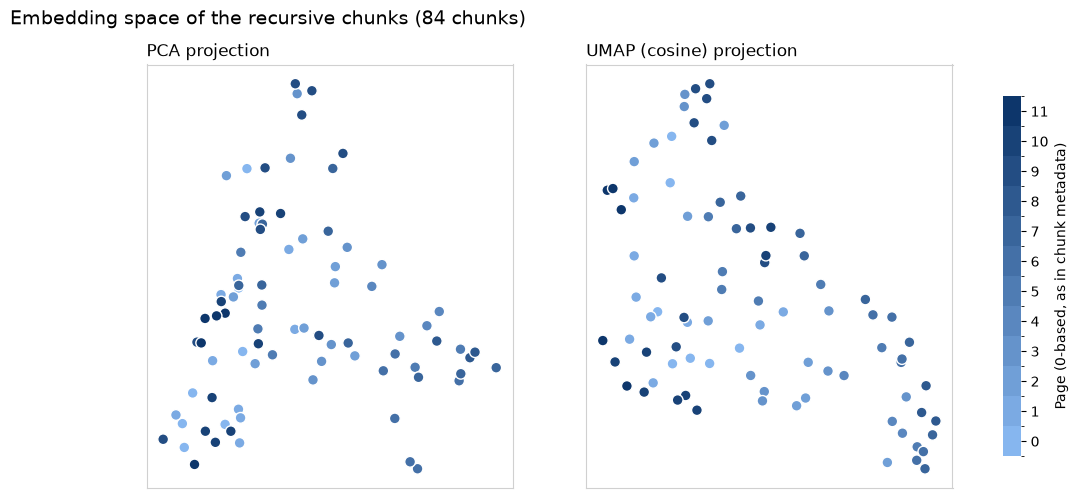

In [60]:
# ── YOUR CODE HERE (bonus) ──────────────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap
from sklearn.decomposition import PCA

try:
    import umap  # optional: UMAP keeps local neighbourhoods better than PCA
except ImportError:
    umap = None


def get_embeddings_and_pages(vectorstore: Chroma) -> tuple[np.ndarray, np.ndarray]:
    """Fetch the raw chunk vectors and their page numbers from a Chroma store.

    Args:
        vectorstore: A LangChain ``Chroma`` vector store that is already indexed.

    Returns:
        A tuple ``(embeddings, pages)`` where ``embeddings`` has shape
        ``(n_chunks, dim)`` and ``pages`` has shape ``(n_chunks,)`` with the
        0-based page number of each chunk (``-1`` if the metadata is missing).
    """
    data = vectorstore._collection.get(include=["embeddings", "metadatas"])
    embeddings = np.asarray(data["embeddings"], dtype=float)
    pages = np.array([meta.get("page", -1) for meta in data["metadatas"]], dtype=int)
    return embeddings, pages


def project_2d(embeddings: np.ndarray, method: str) -> np.ndarray:
    """Project high-dimensional embeddings down to 2D.

    Args:
        embeddings: Array of shape ``(n_chunks, dim)``.
        method: ``"pca"`` (linear, global structure) or ``"umap"`` (non-linear,
            local neighbourhoods).

    Returns:
        Array of shape ``(n_chunks, 2)`` with the 2D coordinates.

    Raises:
        ValueError: If ``method`` is unknown.
    """
    if method == "pca":
        return PCA(n_components=2, random_state=42).fit_transform(embeddings)
    if method == "umap":
        n_neighbors = min(15, len(embeddings) - 1)
        reducer = umap.UMAP(
            n_components=2, n_neighbors=n_neighbors, metric="cosine", random_state=42
        )
        return reducer.fit_transform(embeddings)
    raise ValueError(f"Unknown projection method: {method!r}")


embeddings_rec, pages_rec = get_embeddings_and_pages(vectorstore_recursive)
print(f"Fetched {embeddings_rec.shape[0]} vectors of dimension {embeddings_rec.shape[1]}")

# Pages are ordered, so we use one blue hue from light (first page) to dark (last page)
# and one discrete colour bin per page.
page_values = np.unique(pages_rec)
page_cmap = LinearSegmentedColormap.from_list("pages", ["#86b6ef", "#0d366b"], N=len(page_values))
page_norm = BoundaryNorm(np.arange(page_values.min() - 0.5, page_values.max() + 1.5), page_cmap.N)

methods = ["pca"] + (["umap"] if umap is not None and len(embeddings_rec) > 3 else [])
fig, axes = plt.subplots(1, len(methods), figsize=(6.5 * len(methods), 5.5), squeeze=False)

for ax, method in zip(axes[0], methods):
    coords = project_2d(embeddings_rec, method)
    scatter = ax.scatter(
        coords[:, 0], coords[:, 1],
        c=pages_rec, cmap=page_cmap, norm=page_norm,
        s=60, edgecolors="white", linewidths=1,  # white ring separates overlapping points
    )
    title = "PCA" if method == "pca" else "UMAP (cosine)"
    ax.set_title(f"{title} projection", loc="left", fontsize=12)
    ax.set_xticks([]); ax.set_yticks([])  # projected axes have no physical unit
    for spine in ax.spines.values():
        spine.set_color("#d0d0d0")

colorbar = fig.colorbar(scatter, ax=axes[0].tolist(), ticks=page_values, shrink=0.85)
colorbar.set_label("Page (0-based, as in chunk metadata)")
colorbar.outline.set_visible(False)
fig.suptitle(
    f"Embedding space of the recursive chunks ({len(embeddings_rec)} chunks)",
    x=0.02, ha="left", fontsize=14,
)
plt.show()
# ─────────────────────────────────────────────────────────────────────────────

---
## Checkpoint â€” What you have built

```
  Your PDF
     â”‚
     â–¼
  PyPDFLoader  â”€â”€â–º  pages (Document list)       âœ…
     â”‚
     â”œâ”€â”€â–º RecursiveCharacterTextSplitter  â”€â”€â–º  chunks_recursive   âœ…
     â”‚
     â””â”€â”€â–º SemanticChunker  â”€â”€â–º  chunks_semantic                   âœ…
              â”‚                    â”‚
              â–¼                    â–¼
         ChromaDB              ChromaDB
       (rapport_recursive)   (rapport_semantic)                   âœ…
              â”‚                    â”‚
              â–¼                    â–¼
         retriever_recursive   retriever_semantic                 âœ…
              â”‚
              â–¼
         top-k chunks for any query                               âœ…
```

### In Part 2, you will add:

```
  retriever  â”€â”€â–º  relevant chunks
                       â”‚
                       â–¼
                  LLM (qwen2.5:3b)
                       â”‚
                       â–¼
                  grounded answer
                       â”‚
                       â–¼
                  RAGAS evaluation
                  (faithfulness - context precision - answer relevancy)
```

**Before Part 2:**  
Make sure `chroma_db/` is in the same folder as the Part 2 notebook â€”
you will reload from disk without re-embedding.